# Appendix A — Texture Model (LNDb)
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

> **Why this appendix exists.** The first LNDb tables we downloaded (v2) contained only texture
> ratings, so texture was the project's first target and this notebook was its first model (it was
> then "Notebook 4"). When we found the malignancy ratings in LNDb v4, malignancy became the target
> (Notebooks 1–6). We keep this work as an appendix because texture is clinical context for malignancy
> and because the methods developed here — the score committee, prevalence cut-offs, the referral
> analysis — were reused for malignancy. References to "Notebook 3" below are to the texture version
> of the feature-selection analysis; the selection *settings* are the same. It can be run after
> Notebook 3 (~15–20 min).

---

## Purpose
Notebooks 1–3 turned CT scans into **1136 features per nodule** and showed which of them carry
information about texture. This notebook builds and evaluates the **texture model**: KNN, SVM and
neural-network approaches that rate a nodule as ground-glass, part-solid or solid.

> **Role in the project.** Texture is a known risk factor (part-solid nodules are the most
> suspicious, Notebook 1 §5.2). An earlier version of the malignancy model used this texture model as
> an extra "expert" input; it did not improve malignancy, because the 1136 features already contain
> the texture information.

## The product, in one sentence
> **A second reader that automatically rates the texture of a lung nodule — ground-glass (GGO),
> part-solid or solid — and tells the radiologist when it is unsure.**

Why texture matters: the follow-up a nodule needs (Fleischner Society / Lung-RADS guidelines)
depends on it. **Part-solid nodules carry the highest risk of malignancy** and get their own
management rules, so confusing a part-solid nodule with a solid one changes what happens to the
patient. At the same time, radiologists themselves disagree on texture (Notebook 1), which makes
an objective, reproducible second opinion valuable.

## Constraints we designed for
| Constraint | Consequence in this notebook |
|---|---|
| **Fully automatic** — at test time only the nodule position is known | Every model uses features from *our* segmentation, never the radiologists' masks (section 9 measures what that costs) |
| **Few rare cases** — 38 GGO and 60 part-solid among 768 nodules | Class balancing in every model; metrics that do not reward "always solid" |
| **Patients, not nodules** — one CT can have several nodules | Nodules of the same patient always stay on the same side of every split |
| **Clinicians must trust it** | Interpretable features, importance analysis, and an explicit *"I'm unsure — please check"* signal |
| **Ordinary hardware** | Classic models on a laptop CPU; the full notebook runs in minutes |

## What this notebook contains
| Section | Question |
|---|---|
| 3 | How do we measure success, and what is the bar to beat? |
| 4 | Two baselines: "always solid" and a radiologist's rule of thumb |
| 5 | **Approach A** — classic 3-class classifiers: KNN, SVM, neural network (MLP) |
| 6 | **Approach B** — our approach: predict the radiologists' *score*, not the class |
| 7 | Which approach wins? |
| 8 | Where does the model fail — and do radiologists fail there too? |
| 9 | What does full automation cost? (our segmentation vs radiologist masks) |
| 10 | What did the model learn? (interpretability) |
| 11 | Does it work equally well for every kind of nodule? (fairness / robustness) |
| 12 | Knowing when to ask for help (referral of uncertain cases) |
| 13 | Final texture model (used by Notebook 6) |

**Inputs:** `outputs/features_train.csv`, `outputs/features_train_radiologist.csv` (Notebook 2),
`outputs/selected_features.json` (Notebook 3), `trainset_csv/`
**Outputs:** `outputs/texture_model.joblib` (used by Notebook 6), `outputs/cv_predictions.csv`

> ⏱️ Run time: ~15 minutes on a recent 8-core laptop, longer with fewer cores (almost all of it
> is the nested cross-validation).

---

## 1. Setup

In [1]:
import json
import shutil
import tempfile
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, recall_score

import lndb_utils as U
import lndb_models as M
from lndb_selection import image_type

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
plt.rcParams.update(U.PLOT_STYLE)

# ── Settings ──────────────────────────────────────────────────────────────────
N_JOBS        = -1      # CPU cores for the grid searches (-1 = all)
INNER_SPLITS  = 3       # inner cross-validation folds used to tune the classifiers
N_BOOTSTRAP   = 1000    # resamples for the confidence intervals
REFER_RATE    = 0.20    # share of nodules the model may hand back to the radiologist (section 12)
# ─────────────────────────────────────────────────────────────────────────────

# Pipelines cache their preprocessing steps here, so grid searches that only change the model
# do not recompute feature selection. Temporary: removed at the end of the notebook.
CACHE_DIR = tempfile.mkdtemp(prefix='lndb_nb4_')
memory = Memory(CACHE_DIR, verbose=0)

CLASS_IDS = np.arange(3)
print('Setup complete.')

Setup complete.


## 2. Load the data
Two feature tables describe the same nodules:

- **Automatic** (`features_train.csv`) — features from our own segmentation. This is what the
  final system can compute on a new CT, so **all models are trained and evaluated on it**.
- **Radiologist masks** (`features_train_radiologist.csv`) — features from the radiologists'
  hand-drawn segmentations; only available for the 625 nodules ≥ 3 mm. Used once, in section 9,
  to measure how much automation costs.

We also load every radiologist's **individual** rating, to compare the model with each reader.

In [2]:
train = pd.read_csv(U.OUTPUT_DIR / 'features_train.csv')
train_rad = pd.read_csv(U.OUTPUT_DIR / 'features_train_radiologist.csv')
selection = json.loads((U.OUTPUT_DIR / 'selected_features.json').read_text())

features = [c for c in train.columns if c.startswith(('rad_', 'comp_'))]
assert features == [c for c in train_rad.columns if c.startswith(('rad_', 'comp_'))]

X      = train[features].values
y      = train['texture_class'].values      # 0 GGO · 1 part-solid · 2 solid
score  = train['Text'].values               # radiologists' average rating, 1–5
groups = train['LNDbID'].values             # patient id
FOLDS  = sorted(train['fold'].unique())

# Individual ratings: one row per (nodule, radiologist)
gt = pd.read_csv(U.TRAIN_CSV_DIR / 'trainNodules_gt.csv')
reads = pd.read_csv(U.TRAIN_CSV_DIR / 'trainNodules.csv').set_index(['LNDbID', 'RadID', 'FindingID'])['Text']
readers = []
for row in gt.itertuples():
    for rad, finding in zip(str(row.RadID).split(','), str(row.RadFindingID).split(',')):
        rating = reads.get((row.LNDbID, int(rad), int(finding)))
        if rating is not None and rating > 0:
            readers.append({'LNDbID': row.LNDbID, 'FindingID': row.FindingID,
                            'RadID': int(rad), 'reader_class': U.texture_to_class(rating)})
readers = pd.DataFrame(readers)
n_readers = readers.groupby(['LNDbID', 'FindingID']).size().rename('n_readers')
train = train.merge(n_readers, on=['LNDbID', 'FindingID'], how='left')

print(f'Nodules (automatic features)    : {len(train)}  from {train.LNDbID.nunique()} patients')
print(f'Nodules (radiologist masks)     : {len(train_rad)}')
print(f'Features                        : {len(features)}')
print(f'Classes                         : {dict(train.texture_name.value_counts())}')
print(f'Official folds (nodules)        : {dict(train.fold.value_counts().sort_index())}')
print(f'Selection settings (Notebook 3) : candidates {selection["n_features_candidates"]}, '
      f'|ρ| < {selection["corr_threshold"]}, FDR {selection["fdr_alpha"]}')

Nodules (automatic features)    : 768  from 212 patients
Nodules (radiologist masks)     : 625
Features                        : 1136
Classes                         : {'Solid': 670, 'Part-solid': 60, 'GGO': 38}
Official folds (nodules)        : {0: 199, 1: 193, 2: 185, 3: 191}
Selection settings (Notebook 3) : candidates [5, 10, 20, 50, 100, 'all'], |ρ| < 0.85, FDR 0.05


## 3. How we measure success

### 3.1 Metrics
| Metric | Why |
|---|---|
| **Quadratic weighted kappa (QWK)** | The **official LNDb metric** for texture. Agreement beyond chance, where errors are penalised by the *square* of their distance: GGO↔solid costs 4× more than a neighbour mistake. 0 = chance, 1 = perfect |
| **Balanced accuracy** | Average of the recall of the three classes; "always solid" gets 0.33 however imbalanced the data |
| **Recall per class** | Of the real GGO / part-solid / solid nodules, how many did we catch? Part-solid recall is the clinically critical one |

### 3.2 Validation protocol — nested cross-validation
```
OUTER loop — the 4 official LNDb folds (patients split by the dataset authors)
│   train on 3 folds ────────────────────────────┐
│     INNER loop — grouped CV on those 3 folds    │  chooses hyper-parameters AND the number
│     (patients never split)                      │  of features, using training data only
│   predict the 4th fold, never seen before  ◄───┘
└── repeat for every fold → one honest prediction for every nodule ("out-of-fold")
```
Every number in this notebook is computed from those out-of-fold predictions. Using the
**official folds** makes our results comparable with the LNDb challenge.

**Uncertainty.** With 38 GGO nodules a single number can be lucky. We report a **95% confidence
interval** obtained by resampling *patients* (bootstrap) 1000 times.

### 3.3 The bar to beat: radiologists themselves
Notebook 1 showed that two radiologists rating the same nodule reach a QWK of only ≈ 0.57. That
is the realistic ceiling: a model cannot agree with "the truth" much better than experts agree
with each other.

In [3]:
def outer_cv(fit, Xm=X, data=train):
    """Out-of-fold predictions over the official folds.

    fit(X_train, data_train) must return a fitted model with .predict().
    Returns (predictions for every nodule, {fold: fitted model}).
    """
    pred, models = np.zeros(len(data), dtype=int), {}
    for f in FOLDS:
        tr, te = (data['fold'] != f).values, (data['fold'] == f).values
        models[f] = fit(Xm[tr], data[tr])
        pred[te] = models[f].predict(Xm[te])
    return pred, models


def bootstrap_qwk(y_true, y_pred, patients, n=N_BOOTSTRAP, seed=U.RANDOM_STATE):
    """95% confidence interval of QWK, resampling patients (not nodules)."""
    rng = np.random.default_rng(seed)
    ids = np.unique(patients)
    rows = {p: np.flatnonzero(patients == p) for p in ids}
    stats = [M.qwk(y_true[idx], y_pred[idx])
             for idx in (np.concatenate([rows[p] for p in rng.choice(ids, len(ids))]) for _ in range(n))]
    return np.percentile(stats, [2.5, 97.5])


def evaluate(pred, y_true=y, data=train) -> dict:
    """All the numbers we report for one set of out-of-fold predictions."""
    lo, hi = bootstrap_qwk(y_true, pred, data['LNDbID'].values)
    folds = [M.qwk(y_true[data.fold.values == f], pred[data.fold.values == f]) for f in FOLDS]
    recall = recall_score(y_true, pred, labels=CLASS_IDS, average=None, zero_division=0)
    return {'QWK': M.qwk(y_true, pred), 'QWK 95% CI': f'{lo:.2f} – {hi:.2f}',
            'QWK per fold (mean ± sd)': f'{np.mean(folds):.2f} ± {np.std(folds):.2f}',
            'Balanced acc.': balanced_accuracy_score(y_true, pred),
            **{f'Recall {c}': r for c, r in zip(U.CLASS_NAMES, recall)},
            '_folds': np.array(folds), '_ci': (lo, hi)}


def inner_cv(data):
    """Inner splits: grouped by patient, stratified by class."""
    return list(StratifiedGroupKFold(INNER_SPLITS, shuffle=True, random_state=U.RANDOM_STATE)
                .split(np.zeros(len(data)), data['texture_class'], data['LNDbID']))


results, oof = {}, {}       # metrics and out-of-fold predictions of every approach

Before any model, the human reference — recomputed on **exactly the nodules we model**
(Notebook 1 used every annotated nodule, including those of the CTs we could not process):

In [4]:
pairs = []
for _, g in readers.merge(train[['LNDbID', 'FindingID']]).groupby(['LNDbID', 'FindingID']):
    c = g['reader_class'].values
    pairs += [(c[i], c[j]) for i in range(len(c)) for j in range(i + 1, len(c))]
pairs = np.array(pairs)
HUMAN_QWK = M.qwk(pairs[:, 0], pairs[:, 1])
print(f'Radiologist vs radiologist: QWK = {HUMAN_QWK:.3f}  ({len(pairs)} pairs of readers, '
      f'{(train.n_readers >= 2).sum()} nodules with 2+ readers)')

Radiologist vs radiologist: QWK = 0.566  (309 pairs of readers, 221 nodules with 2+ readers)


## 4. Baselines
A model is only useful if it beats something simple. Two references:

1. **Always "solid"** — the majority class. It is right 87% of the time, which shows why accuracy
   is a misleading metric here: its QWK is 0.
2. **A radiologist's rule of thumb** — texture is, by definition, *how much of the nodule is
   solid*. Notebook 2 measured exactly that: `comp_solid_fraction`, the share of the nodule's
   voxels denser than −300 HU. The rule uses that **single number**: the least solid nodules are
   called GGO, the next ones part-solid, the rest solid — in the same proportions as in the training
   folds (the same cut-off method as our final model, section 6). If a complex model cannot beat one interpretable number, it is not worth
   its complexity.

In [5]:
class SolidFractionRule(BaseEstimator, ClassifierMixin):
    """Class from the solid fraction alone; cut-offs reproduce the training class proportions."""

    def fit(self, X, y):
        self.thresholds_ = M.prevalence_thresholds(self._fraction(X), y)
        return self

    def predict(self, X):
        return M.score_to_class(self._fraction(X), self.thresholds_)

    @staticmethod
    def _fraction(X):
        return X[:, features.index('comp_solid_fraction')]


oof['Always solid'], _ = outer_cv(lambda Xt, dt: DummyClassifier(strategy='most_frequent')
                                  .fit(Xt, dt.texture_class))
oof['Solid-fraction rule'], rule_models = outer_cv(lambda Xt, dt: SolidFractionRule().fit(Xt, dt.texture_class.values))
for name in ['Always solid', 'Solid-fraction rule']:
    results[name] = evaluate(oof[name])

cutoffs = pd.DataFrame({f: np.round(m.thresholds_, 3) for f, m in rule_models.items()},
                       index=['GGO → part-solid if solid fraction ≥', 'part-solid → solid if solid fraction >']).T
cutoffs.index.name = 'test fold'
cutoffs

,GGO → part-solid if solid fraction ≥,part-solid → solid if solid fraction >
test fold,,
0,0.028,0.109
1,0.037,0.122
2,0.033,0.104
3,0.032,0.125


**Reading the cut-offs.** They are stable across folds: a nodule is called GGO when less
than ~3% of its segmented voxels are solid, and solid when more than ~10–12% are. The solid
fraction of *solid* nodules varies a lot (median ≈ 0.45, but some are much lower, because our
segmentation includes the nodule's soft border), so the rule has to call "solid" early. Even so,
this single, fully interpretable number reaches a QWK of ≈ 0.45 (section 7) — the bar every
model below must clear.

## 5. Approach A — classic 3-class classifiers

### 5.1 The three models
| Model | Idea | Weak spot here |
|---|---|---|
| **KNN** | A nodule gets the class of its *k* most similar nodules | "Similar" is computed over every feature equally — irrelevant features dilute the distance |
| **SVM** (RBF kernel) | Finds the boundary with the widest margin between classes, allowing curved boundaries | Needs scaled features; slower with many nodules (not an issue at 768) |
| **MLP** (neural network) | Layers of neurons learn combinations of features | Many parameters for few examples → strong regularisation (`alpha`) needed |
| *Logistic regression* | *Linear reference — the probe used in Notebook 3* | |

### 5.2 One pipeline per model
```
impute → select (relevance + redundancy) → keep first k → quantile → standardise → [SMOTE] → model
```
- **Feature selection is a tuned hyper-parameter.** Notebook 3 showed that the best number of
  features depends on the model, so each grid search tries the candidates Notebook 3 saved in
  `selected_features.json` (k ∈ {5, 10, 20, 50, 100} **and** "all 1136"), with the same
  relevance and redundancy settings — the two notebooks cannot drift apart.
- **Class imbalance:** SVM and logistic regression weight errors on rare classes more
  (`class_weight='balanced'`); KNN and MLP don't support weights, so **SMOTE** creates synthetic
  GGO / part-solid examples — inside the pipeline, so only from training nodules.
- **Imputation** fills any feature that failed to compute on a test CT; on the training data
  there is nothing to fill.
- Hyper-parameters are chosen by the inner loop to maximise **QWK**.

In [6]:
CLASSIFIERS = ['KNN', 'SVM', 'MLP', 'LogReg']
chosen = []

for name in CLASSIFIERS:
    pipe, grid = M.make_classifier(name, selection=selection, memory=memory)

    def fit(Xt, dt, pipe=pipe, grid=grid):
        search = GridSearchCV(pipe, grid, scoring=M.QWK_SCORER, cv=inner_cv(dt), n_jobs=N_JOBS)
        return search.fit(Xt, dt['texture_class'].values)

    oof[name], searches = outer_cv(fit)
    results[name] = evaluate(oof[name])
    chosen += [{'model': name, 'test fold': f, **M.describe_params(s.best_params_)} for f, s in searches.items()]

pd.DataFrame(chosen).set_index(['model', 'test fold']).fillna('')

n_neighbors n_features     C  gamma alpha hidden_layer_sizes
model  test fold                                                             
KNN    0                 5.0         50                                      
       1                 5.0        100                                      
       2                31.0         50                                      
       3                 5.0        100                                      
SVM    0                             50  10.0  scale                         
       1                            all  10.0  scale                         
       2                            100  10.0  scale                         
       3                            all  10.0  scale                         
MLP    0                            100                1.0              (32,)
       1                            all                1.0           (64, 32)
       2                            100                1.0           (64, 32)
       3                            100                1.0           (64, 32)
LogReg 0                            100   0.5                                
       1                            all   0.5                                
       2                            all   0.5                                
       3                            all   0.5

**What the grid searches chose.** The inner loop, which never sees the test fold, makes
choices that match Notebook 3: **KNN prefers fewer features** (50–100 — its distance is diluted by
irrelevant ones), while the regularised models (**SVM**, **logistic regression**, **MLP**) mostly
choose 100 features or all 1136, because their regularisation can exploit many weak, complementary
features. The scores are compared with everything else in section 7.

## 6. Approach B — predict the score, not the class (our approach)

### 6.1 The idea
Approach A throws information away. The label of each nodule comes from an **average** of
radiologist ratings: a nodule rated 3.67 (two readers said 4, one said 3) and one rated 5.0
(everyone said 5) are both just "solid". And a classifier does not know that the classes are
**ordered** — mistaking GGO for solid is worse than GGO for part-solid.

So we let each model learn the **score itself** (regression on the 1–5 average), and only then
turn the score into a class:

```
features ──► KNN regressor ─┐
features ──► SVM regressor ─┼─► average score ──► two learned cut-offs ──► GGO / part-solid / solid
features ──► MLP regressor ─┘
```

Three design choices, each with a reason:

1. **Regression on the average rating** — keeps the "almost solid" information and the order of
   the classes. The models are tuned on how well their score *ranks* the nodules (correlation).
2. **A committee of the three models** — they make different kinds of errors (neighbours,
   margins, learned combinations), so their average is steadier than any one of them. It is the
   same principle the dataset uses for its labels: averaging several readers.
3. **Cut-offs that respect the class proportions** — the official cut-offs (2.33 / 3.67) were
   defined for averages of *human* ratings. Model scores are "shrunk" towards the frequent solid
   class (a regression hedges towards the average), so those cut-offs fit them badly. Instead,
   using **out-of-fold** scores inside the training data (never the test fold), we place the
   cut-offs so the model predicts each class **as often as the radiologists assign it**: the
   lowest 4.9% of scores → GGO, the next 7.8% → part-solid, the rest → solid. Section 6.3 compares
   this with two alternatives. Rare classes are also up-weighted in the SVM and MLP members.

The whole procedure is one estimator, `TextureScoreCommittee` in `lndb_models.py`, so that
exactly the same code runs inside cross-validation and for the final model.

In [7]:
oof['Score committee'], committees = outer_cv(
    lambda Xt, dt: M.TextureScoreCommittee(selection=selection, n_jobs=N_JOBS, memory=memory)
                    .fit(Xt, dt['Text'].values, dt['LNDbID'].values))
results['Score committee'] = evaluate(oof['Score committee'])

# Out-of-fold continuous scores of the committee and of each member
oof_score = np.zeros(len(train))
member_pred = {m: np.zeros(len(train), dtype=int) for m in ['KNN', 'SVM', 'MLP']}
fold_thresholds = {}
for f, c in committees.items():
    te = (train.fold == f).values
    oof_score[te] = c.predict_score(X[te])
    for m, p in c.predict_members(X[te]).items():
        member_pred[m][te] = p
    fold_thresholds[f] = c.thresholds_

pd.DataFrame([{'test fold': f, 'cut-off GGO | part-solid': c.thresholds_[0],
               'cut-off part-solid | solid': c.thresholds_[1],
               **{f'{m}': ', '.join(f'{k}={v}' for k, v in p.items()) for m, p in c.best_params_.items()}}
              for f, c in committees.items()]).set_index('test fold')

,cut-off GGO | part-solid,cut-off part-solid | solid,KNN,SVM,MLP
test fold,,,,,
0,2.673,3.647,"n_neighbors=15, n_features=50","C=10, n_features=all","alpha=1.0, n_features=all"
1,2.869,3.601,"n_neighbors=15, n_features=100","C=10, n_features=all","alpha=10.0, n_features=all"
2,2.991,3.695,"n_neighbors=15, n_features=100","C=10, n_features=all","alpha=1.0, n_features=all"
3,3.068,3.620,"n_neighbors=31, n_features=50","C=10, n_features=all","alpha=1.0, n_features=all"


### 6.2 What does each idea contribute?
The committee also stores each member's own cut-offs, so every member can be evaluated **alone**
on the same out-of-fold nodules. The table separates the two ideas:

- **left → middle column** (same algorithm): the effect of predicting the ordered score
  instead of three unordered classes;
- **middle column → last row**: the effect of averaging the three models.

In [8]:
ablation = pd.DataFrame({
    'as 3-class classifier (section 5)': {m: results[m]['QWK'] for m in member_pred},
    'as score model, alone': {m: M.qwk(y, p) for m, p in member_pred.items()},
})
ablation.loc['Committee (average of the 3)'] = [np.nan, results['Score committee']['QWK']]
ablation.style.format('{:.3f}', na_rep='—').set_caption('Out-of-fold QWK')

,as 3-class classifier (section 5),"as score model, alone"
KNN,0.289,0.561
SVM,0.539,0.565
MLP,0.518,0.417
Committee (average of the 3),—,0.587


**Both ideas help, the first one most.** Predicting the ordered score improves every
algorithm — dramatically for KNN, whose QWK more than doubles: as a regressor, its neighbours'
*average* score is informative even when no neighbour has the right class. Averaging the three
score models then beats each of them alone.

### 6.3 How to turn the score into a class?
Three ways to place the two cut-offs, all computed from the same out-of-fold committee scores:

| Strategy | How the cut-offs are chosen |
|---|---|
| **Official** | 2.33 / 3.67, the LNDb rule for averaging human ratings |
| **QWK-optimised** | The pair that maximises QWK on the inner out-of-fold scores (median over 25 bootstrap resamples, for stability) |
| **Prevalence matching** *(ours)* | Each class predicted as often as in the training data |

In [9]:
strategy_rows = []
for strategy, rule in M.CUTOFF_STRATEGIES.items():
    pred, cut = np.zeros(len(train), dtype=int), []
    for f, c in committees.items():
        te = (train.fold == f).values
        t = rule(np.mean(list(c.oof_scores_.values()), axis=0), c.oof_classes_)
        pred[te] = M.score_to_class(oof_score[te], t)
        cut.append(t)
    cut = np.array(cut)
    strategy_rows.append({'cut-offs': strategy, 'QWK': M.qwk(y, pred),
                          'Balanced acc.': balanced_accuracy_score(y, pred),
                          'Recall part-solid': recall_score(y, pred, labels=[1], average=None)[0],
                          'predicted part-solid': int((pred == 1).sum()),
                          'cut-off spread over folds': f'± {cut.std(axis=0).max():.2f}'})
pd.DataFrame(strategy_rows).set_index('cut-offs').rename(
    index={'official': 'Official (2.33 / 3.67)', 'qwk': 'QWK-optimised', 'prevalence': 'Prevalence matching (ours)'}
).style.format({'QWK': '{:.3f}', 'Balanced acc.': '{:.3f}', 'Recall part-solid': '{:.2f}'})

,QWK,Balanced acc.,Recall part-solid,predicted part-solid,cut-off spread over folds
cut-offs,,,,,
Official (2.33 / 3.67),0.523,0.505,0.37,81,± 0.00
QWK-optimised,0.597,0.570,0.17,32,± 0.09
Prevalence matching (ours),0.587,0.571,0.22,51,± 0.15


**Why prevalence matching?** In cross-validation, QWK-optimised and prevalence-matched
cut-offs perform about the same (QWK ≈ 0.60 vs 0.59), both clearly better than the official cut-offs. But
the QWK-optimised cut-offs win partly by **rarely predicting the middle class**: they predict only
32 part-solid nodules (60 real ones) and catch 17% of them. QWK can be "won" by squeezing the
middle class, and how far that goes is unpredictable: with an earlier, smaller version of the data
(709 nodules, before 13 missing CTs were recovered) the final model's QWK-optimised cut-offs left
only 17 part-solid predictions for 58 real ones. Prevalence matching cannot do that: every class keeps its share, the cut-offs
optimise nothing that could over-fit, and the rule is easy to explain to a clinician.

**A trade-off to make explicit.** The official cut-offs catch the most part-solid nodules
(recall 0.37 vs 0.22) at the cost of QWK. Which operating point to use is a **clinical decision**,
not a technical one: a screening programme worried about missing part-solid nodules could choose a
wider part-solid band, accepting more false alarms. We use the official LNDb texture metric (QWK) to choose,
and report the alternative.

### 6.4 What the committee's score looks like
Each dot is one nodule, placed at its out-of-fold committee score and coloured by its true class;
the dashed lines are the cut-offs (averaged over folds).

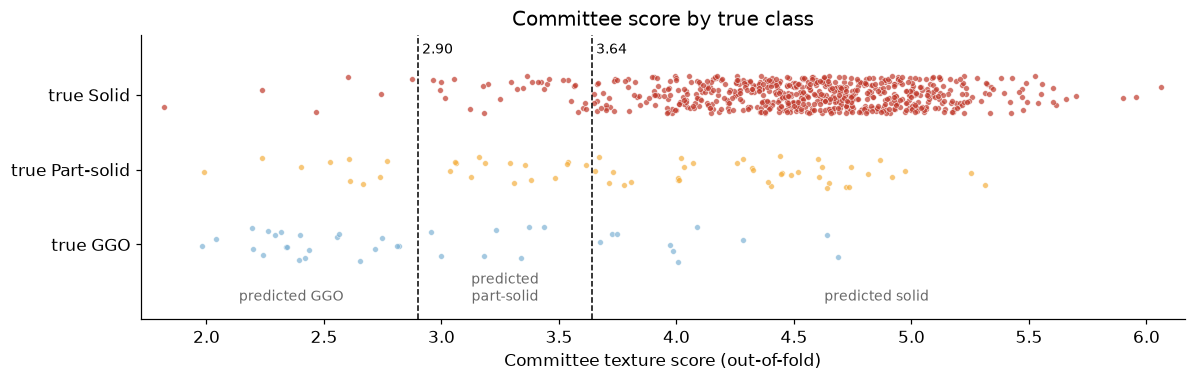

In [10]:
low, high = np.mean(list(fold_thresholds.values()), axis=0)
rng = np.random.default_rng(U.RANDOM_STATE)

fig, ax = plt.subplots(figsize=(11, 3.6))
for k, name in enumerate(U.CLASS_NAMES):
    s = oof_score[y == k]
    ax.scatter(s, k + rng.uniform(-0.25, 0.25, len(s)), s=14, alpha=0.7,
               color=U.CLASS_COLORS[name], edgecolor='white', linewidth=0.4)
for t in (low, high):
    ax.axvline(t, color='black', ls='--', lw=1)
ax.text(low, 2.55, f' {low:.2f}', fontsize=9); ax.text(high, 2.55, f' {high:.2f}', fontsize=9)
for x0, txt in [((oof_score.min() + low) / 2, 'predicted GGO'), ((low + high) / 2, 'predicted\npart-solid'),
                ((high + oof_score.max()) / 2, 'predicted solid')]:
    ax.text(x0, -0.75, txt, ha='center', fontsize=9, color='dimgray')
ax.set(yticks=range(3), yticklabels=[f'true {n}' for n in U.CLASS_NAMES],
       xlim=(oof_score.min() - 0.1, oof_score.max() + 0.1), ylim=(-1, 2.8),
       xlabel='Committee texture score (out-of-fold)', title='Committee score by true class')
plt.tight_layout(); plt.show()

Solid nodules pile up at the right and GGO nodules spread to the left — the score orders
the nodules the way radiologists do. The part-solid nodules sit in the middle **but overlap
heavily with solid ones**: that overlap is the main source of error, examined in section 8.

## 7. Which approach wins?

In [11]:
ORDER = ['Always solid', 'Solid-fraction rule', 'KNN', 'SVM', 'MLP', 'LogReg', 'Score committee']
table = pd.DataFrame({k: {m: v for m, v in results[k].items() if not m.startswith('_')} for k in ORDER}).T
table.index.name = 'approach'
table.style.format({c: '{:.3f}' for c in ['QWK', 'Balanced acc.'] + [f'Recall {n}' for n in U.CLASS_NAMES]})

,QWK,QWK 95% CI,QWK per fold (mean ± sd),Balanced acc.,Recall GGO,Recall Part-solid,Recall Solid
approach,,,,,,,
Always solid,0.000,0.00 – 0.00,0.00 ± 0.00,0.333,0.000,0.000,1.000
Solid-fraction rule,0.452,0.34 – 0.54,0.45 ± 0.03,0.501,0.474,0.117,0.912
KNN,0.289,0.20 – 0.37,0.29 ± 0.02,0.550,0.658,0.350,0.643
SVM,0.539,0.41 – 0.64,0.53 ± 0.11,0.551,0.500,0.200,0.952
MLP,0.518,0.40 – 0.61,0.52 ± 0.11,0.526,0.526,0.133,0.919
LogReg,0.434,0.32 – 0.52,0.43 ± 0.07,0.509,0.474,0.183,0.869
Score committee,0.587,0.46 – 0.68,0.58 ± 0.09,0.571,0.553,0.217,0.943


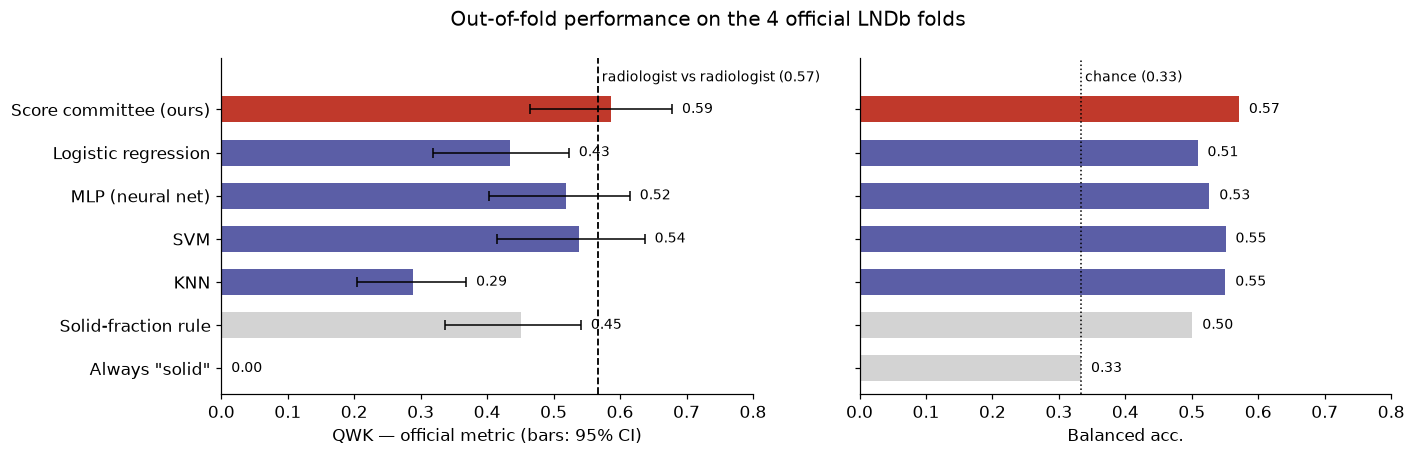

In [12]:
labels = {'KNN': 'KNN', 'SVM': 'SVM', 'MLP': 'MLP (neural net)', 'LogReg': 'Logistic regression',
          'Always solid': 'Always "solid"', 'Solid-fraction rule': 'Solid-fraction rule',
          'Score committee': 'Score committee (ours)'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ypos = np.arange(len(ORDER))
for ax, metric in zip(axes, ['QWK', 'Balanced acc.']):
    vals = [results[k][metric] for k in ORDER]
    colors = [U.COLOR_ACCENT if k == 'Score committee' else
              ('lightgray' if k in ('Always solid', 'Solid-fraction rule') else U.COLOR_NEUTRAL) for k in ORDER]
    ax.barh(ypos, vals, color=colors, height=0.6)
    if metric == 'QWK':
        lo = [v - results[k]['_ci'][0] for k, v in zip(ORDER, vals)]
        hi = [results[k]['_ci'][1] - v for k, v in zip(ORDER, vals)]
        ax.errorbar(vals, ypos, xerr=[lo, hi], fmt='none', ecolor='black', lw=1, capsize=3)
        ax.axvline(HUMAN_QWK, color='black', ls='--', lw=1.2)
        ax.text(HUMAN_QWK, len(ORDER) - 0.35, f' radiologist vs radiologist ({HUMAN_QWK:.2f})', fontsize=9)
    else:
        ax.axvline(1 / 3, color='black', ls=':', lw=1)
        ax.text(1 / 3, len(ORDER) - 0.35, ' chance (0.33)', fontsize=9)
    for yi, k, v in zip(ypos, ORDER, vals):
        end = results[k]['_ci'][1] if metric == 'QWK' else v      # write the value after the CI bar
        ax.text(max(end, 0) + 0.015, yi, f'{v:.2f}', fontsize=9, va='center')
    ax.set(xlabel=metric + (' — official metric (bars: 95% CI)' if metric == 'QWK' else ''), xlim=(0, 0.8))
axes[0].set_yticks(ypos, [labels[k] for k in ORDER])
axes[0].set_ylim(-0.6, len(ORDER) + 0.2)
fig.suptitle('Out-of-fold performance on the 4 official LNDb folds')
plt.tight_layout(); plt.show()

In [13]:
best_classifier = max(['KNN', 'SVM', 'MLP'], key=lambda k: results[k]['QWK'])
d = results['Score committee']['_folds'] - results[best_classifier]['_folds']
print(f'Committee vs best classifier ({best_classifier}), QWK per official fold: '
      f'{np.round(d, 3)}  → better in {np.sum(d > 0)}/4 folds, mean {d.mean():+.3f}')
d = results['Score committee']['_folds'] - results['Solid-fraction rule']['_folds']
print(f'Committee vs solid-fraction rule, QWK per official fold:            '
      f'{np.round(d, 3)}  → better in {np.sum(d > 0)}/4 folds, mean {d.mean():+.3f}')

Committee vs best classifier (SVM), QWK per official fold: [0.017 0.137 0.017 0.01 ]  → better in 4/4 folds, mean +0.045
Committee vs solid-fraction rule, QWK per official fold:            [0.051 0.105 0.063 0.275]  → better in 4/4 folds, mean +0.123


### Reading the results
- **Accuracy would have lied.** "Always solid" is right for 87% of nodules but has QWK 0 and
  never finds a single GGO or part-solid nodule.
- **One interpretable feature already goes a long way.** The solid-fraction rule (QWK ≈ 0.45)
  beats KNN and is close to logistic regression as classifiers.
- **KNN struggles as a classifier** (≈ 0.29): the rare classes have too few neighbours to win a vote.
- **SVM is the best classic classifier** (≈ 0.54), followed by the MLP (≈ 0.52).
- **Our score committee is the best approach** (≈ 0.59), better than the SVM and than the rule in
  all 4 official folds, and **at the level of the agreement between two radiologists** (≈ 0.57).

> **Caveat on certainty.** With only 4 outer folds and 38 GGO nodules, the confidence intervals
> overlap: the ranking among the stronger approaches is suggestive, not proven. What *is* clear
> is that every learned model beats "always solid", and that the committee is consistently at
> least as good as the alternatives.

## 8. Where does the model fail — and do radiologists fail there too?

### 8.1 Confusion matrices

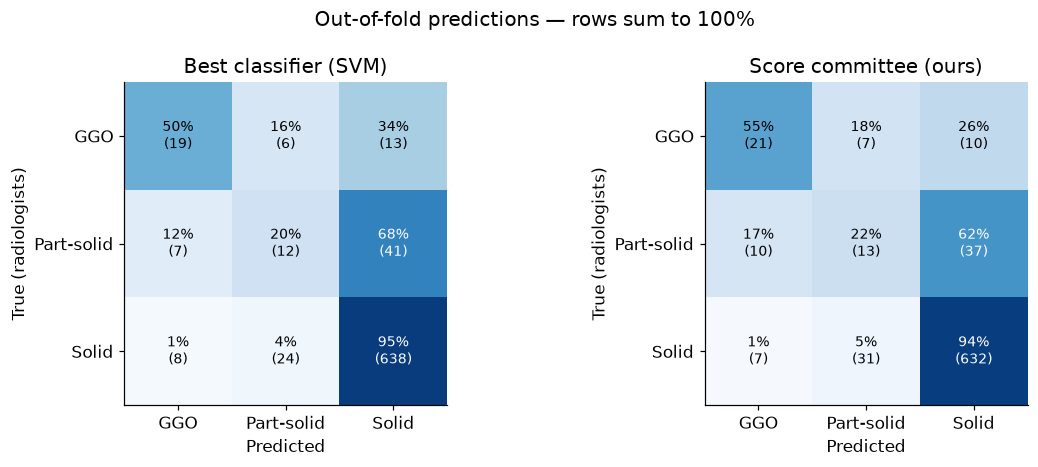

In [14]:
def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{share[i, j]:.0%}\n({cm[i, j]})', ha='center', va='center', fontsize=9,
                    color='white' if share[i, j] > 0.6 else 'black')
    ax.set_xticks(range(3), U.CLASS_NAMES); ax.set_yticks(range(3), U.CLASS_NAMES)
    ax.set(xlabel='Predicted', ylabel='True (radiologists)', title=title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
plot_confusion(axes[0], y, oof[best_classifier], f'Best classifier ({best_classifier})')
plot_confusion(axes[1], y, oof['Score committee'], 'Score committee (ours)')
fig.suptitle('Out-of-fold predictions — rows sum to 100%')
plt.tight_layout(); plt.show()

**Reading the matrices:** each row is a true class; the diagonal is what we got right.
- **Solid** nodules are almost always recognised (94%).
- The committee finds **more GGO nodules** than the SVM (55% vs 50%), mainly by no longer calling
  them solid.
- **Part-solid is the weak point of every model**: more than half are called solid. It is the
  same pair Notebook 3 found hardest to separate with any feature (AUC ≈ 0.69) and the pair
  radiologists disagree on most (Notebook 1). Section 6.3 showed this can be traded against QWK
  by widening the part-solid band.

### 8.2 The model as one more radiologist
The fairest comparison: on nodules read by two or more radiologists, compare the model's class
with **each individual reader's** class, exactly as we compared readers with each other.

In [15]:
pred_df = train[['LNDbID', 'FindingID', 'n_readers']].assign(model=oof['Score committee'])
multi = readers.merge(pred_df[pred_df.n_readers >= 2], on=['LNDbID', 'FindingID'])

comparison = pd.DataFrame({
    'QWK': [HUMAN_QWK, M.qwk(multi.reader_class, multi.model)],
    'exact agreement': [(pairs[:, 0] == pairs[:, 1]).mean(), (multi.reader_class == multi.model).mean()],
    'pairs compared': [len(pairs), len(multi)],
}, index=['radiologist vs radiologist', 'model vs radiologist']).round(3)
comparison

,QWK,exact agreement,pairs compared
radiologist vs radiologist,0.566,0.926,309
model vs radiologist,0.617,0.916,486


The model agrees with an individual radiologist about as often as two radiologists agree
with each other (exact agreement ≈ 92% vs 93%), and with a slightly **higher** QWK (≈ 0.62 vs
0.57): on this comparison it behaves **like a second human reader**.

### 8.3 Is the model wrong where radiologists disagree?
For nodules read by 2+ radiologists we split them in two groups: those where all readers gave
the **same class** and those where they **disagreed**. If the model's errors concentrate in the
second group, they reflect genuine ambiguity in the image rather than a failure of the model.

In [16]:
agree = readers.groupby(['LNDbID', 'FindingID'])['reader_class'].nunique().eq(1).rename('readers_agree')
sub = train[['LNDbID', 'FindingID', 'n_readers', 'texture_class']].assign(
    model=oof['Score committee']).merge(agree, on=['LNDbID', 'FindingID'])
sub = sub[sub.n_readers >= 2]
summary = sub.groupby('readers_agree').apply(lambda g: pd.Series({
    'nodules': len(g),
    'model correct': (g.model == g.texture_class).mean(),
    'part-solid share': (g.texture_class == 1).mean()}))
summary.index = summary.index.map({True: 'radiologists agreed', False: 'radiologists disagreed'})
summary.style.format({'nodules': '{:.0f}', 'model correct': '{:.0%}', 'part-solid share': '{:.0%}'})

,nodules,model correct,part-solid share
readers_agree,,,
radiologists disagreed,19,37%,58%
radiologists agreed,202,95%,3%


When radiologists agree, the model is usually right; when they disagree, the model's accuracy
drops sharply — and those nodules are mostly part-solid. The model's hardest cases are the
humans' hardest cases. This matters for the product: the model should **flag** such nodules
rather than pretend to be certain (section 12).

## 9. What does full automation cost?
At test time nobody draws the nodule for us, so every model uses **our automatic segmentation**
(Notebook 2; median Dice ≈ 0.68 against the radiologists). How much performance does that cost?

We train and evaluate the **same committee, on the same 625 nodules** (those with a radiologist
mask), twice: once with features from the radiologists' masks, once with features from our
segmentation. Same folds, same nodules — the only difference is who drew the outline.

In [17]:
keys = ['LNDbID', 'FindingID']
paired_auto = train.merge(train_rad[keys], on=keys).sort_values(keys).reset_index(drop=True)
paired_rad = train_rad.sort_values(keys).reset_index(drop=True)
assert (paired_auto[keys].values == paired_rad[keys].values).all()

def committee_fit(Xt, dt):
    return M.TextureScoreCommittee(selection=selection, n_jobs=N_JOBS, memory=memory).fit(Xt, dt['Text'].values, dt['LNDbID'].values)

y_paired = paired_auto['texture_class'].values
automation = {}
for label, data in [('Radiologist masks', paired_rad), ('Automatic segmentation', paired_auto)]:
    pred, _ = outer_cv(committee_fit, data[features].values, data)
    automation[label] = evaluate(pred, y_paired, data)

pd.DataFrame({k: {m: v for m, v in r.items() if not m.startswith('_')} for k, r in automation.items()}).T \
  .style.format({c: '{:.3f}' for c in ['QWK', 'Balanced acc.'] + [f'Recall {n}' for n in U.CLASS_NAMES]})

,QWK,QWK 95% CI,QWK per fold (mean ± sd),Balanced acc.,Recall GGO,Recall Part-solid,Recall Solid
Radiologist masks,0.706,0.59 – 0.79,0.70 ± 0.05,0.658,0.667,0.364,0.942
Automatic segmentation,0.663,0.55 – 0.75,0.66 ± 0.06,0.621,0.636,0.291,0.937


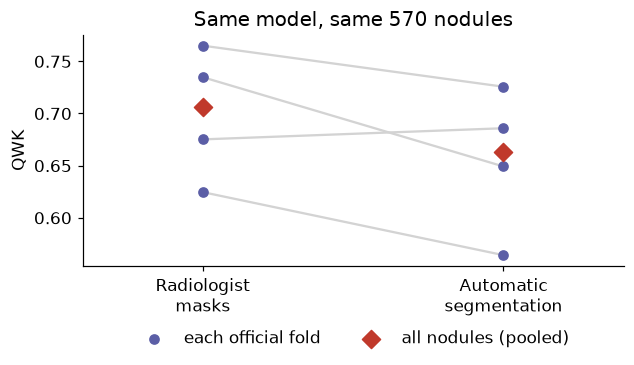

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.8))
a, b = automation['Radiologist masks']['_folds'], automation['Automatic segmentation']['_folds']
for f in range(len(FOLDS)):
    ax.plot([0, 1], [a[f], b[f]], color='lightgray', zorder=1)
ax.scatter(np.zeros(len(a)), a, color=U.COLOR_NEUTRAL, zorder=2, label='each official fold')
ax.scatter(np.ones(len(b)), b, color=U.COLOR_NEUTRAL, zorder=2)
ax.scatter([0, 1], [automation['Radiologist masks']['QWK'], automation['Automatic segmentation']['QWK']],
           marker='D', s=70, color=U.COLOR_ACCENT, zorder=3, label='all nodules (pooled)')
ax.set(xticks=[0, 1], xticklabels=['Radiologist\nmasks', 'Automatic\nsegmentation'], xlim=(-0.4, 1.4),
       ylabel='QWK', title=f'Same model, same {len(paired_auto)} nodules')
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.42), ncol=2)
plt.tight_layout(); plt.show()

This quantifies the **cost of automation**: with the radiologists' outlines the same model
reaches QWK ≈ 0.71; with our automatic segmentation ≈ 0.66. Automation costs about **0.04 of QWK**
— real (the radiologist masks win in 3 of 4 folds), but small enough that a fully automatic
system remains useful. The fold-to-fold spread is large, so the exact size of the gap is
uncertain. Section 11 confirms the picture from the other side: nodules where our segmentation
disagrees with the radiologist (low Dice) are rated less accurately. **Better segmentation is
therefore a worthwhile next step** — for example a model trained on the LIDC-IDRI masks.

## 10. What did the model learn? (interpretability)

### 10.1 Grouped permutation importance
For a model that uses 1136 features, "the importance of feature #734" is meaningless. Instead we
ask **which kind of information** the model relies on. For each group of features we shuffle
**all of them together** across the nodules of the test fold (so the group carries no information
any more, while the model stays unchanged) and measure how much the agreement between the
committee's score and the radiologists' score drops (Spearman ρ). Shuffling a whole group at
once avoids the classic trap of correlated features "covering" for each other.

Groups are defined two ways: by **image version** (original / wavelet / LoG / composition) and by
**feature family** (first-order intensity, shape, and the five texture matrices).

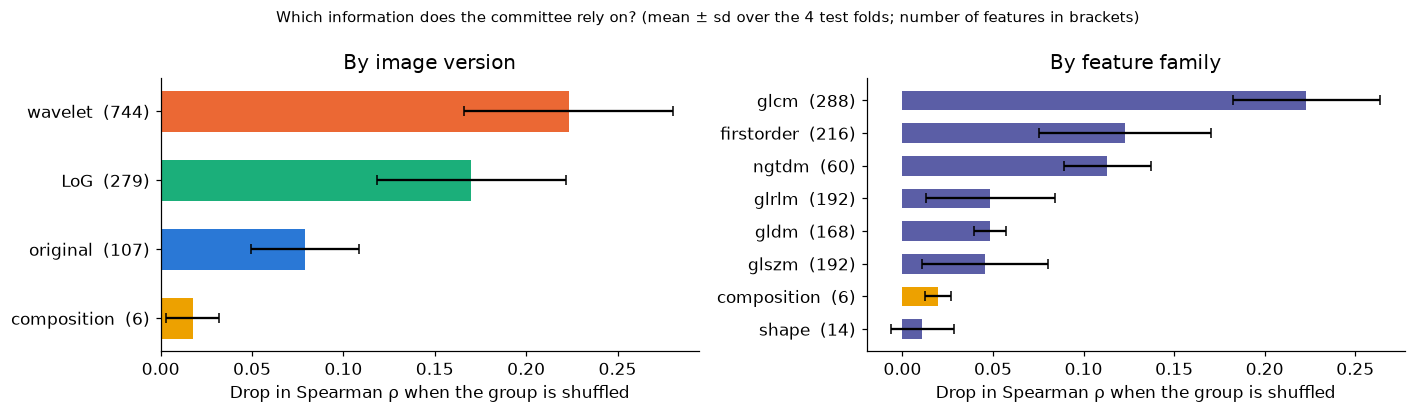

In [19]:
def feature_family(f):
    return 'composition' if f.startswith('comp_') else f.split('_')[2]

GROUPINGS = {'image version': {g: [i for i, f in enumerate(features) if image_type(f) == g]
                               for g in ['original', 'wavelet', 'LoG', 'composition']},
             'feature family': {g: [i for i, f in enumerate(features) if feature_family(f) == g]
                                for g in ['composition', 'firstorder', 'shape', 'glcm', 'glrlm',
                                          'glszm', 'gldm', 'ngtdm']}}
N_SHUFFLES = 5
rng = np.random.default_rng(U.RANDOM_STATE)
importance = []
for f, c in committees.items():
    te = (train.fold == f).values
    Xte, s_true = X[te], score[te]
    base = spearmanr(c.predict_score(Xte), s_true)[0]
    for grouping, groups_ in GROUPINGS.items():
        for g, cols in groups_.items():
            drops = []
            for _ in range(N_SHUFFLES):
                Xp = Xte.copy()
                Xp[:, cols] = Xte[rng.permutation(len(Xte))][:, cols]   # same shuffle for the whole group
                drops.append(base - spearmanr(c.predict_score(Xp), s_true)[0])
            importance.append({'grouping': grouping, 'group': g, 'fold': f, 'drop': np.mean(drops)})
importance = pd.DataFrame(importance)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (grouping, groups_) in zip(axes, GROUPINGS.items()):
    imp = importance[importance.grouping == grouping].groupby('group')['drop'].agg(['mean', 'std'])
    imp = imp.reindex(groups_).sort_values('mean')
    color = [U.SOURCE_COLORS.get(g, U.COLOR_NEUTRAL) if grouping == 'image version' else
             (U.SOURCE_COLORS['composition'] if g == 'composition' else U.COLOR_NEUTRAL) for g in imp.index]
    ax.barh(imp.index, imp['mean'], xerr=imp['std'], color=color, ecolor='black', capsize=3, height=0.6)
    ax.set_yticks(range(len(imp)), [f'{g}  ({len(groups_[g])})' for g in imp.index])
    ax.set(xlabel='Drop in Spearman ρ when the group is shuffled', title=f'By {grouping}')
fig.suptitle('Which information does the committee rely on? (mean ± sd over the 4 test folds; '
             'number of features in brackets)', fontsize=10)
plt.tight_layout(); plt.show()

**How to read it:** a longer bar means the model gets worse when that information is
destroyed.

- **Filtered images carry most of the signal.** Shuffling the wavelet or the LoG features hurts
  far more than shuffling the original-image features. This is the justification for extracting
  ~1000 features instead of the ~100 of the original image: the texture of nodules shows up at
  specific scales and frequencies that the filters isolate.
- **Texture matrices matter most**, above all GLCM (how often grey levels appear next to each
  other), then first-order intensity and NGTDM (how different a voxel is from its neighbours).
  Shape barely matters — texture is about *what is inside* the nodule, not its outline.
- **Composition looks small, but per feature it is not.** The 6 composition features cause a drop
  about half as large as families of ~170–190 features. Their group is small because the same information
  (how dense the nodule is) is also present in hundreds of intensity and texture features, which
  take over when composition is shuffled. Importance here means *irreplaceable*, not *useful*.

### 10.2 Does the model follow radiological common sense?
Texture is defined by how much of the nodule is solid. Plotting the committee's score against the
solid fraction of our segmentation shows how the model relates to that definition:

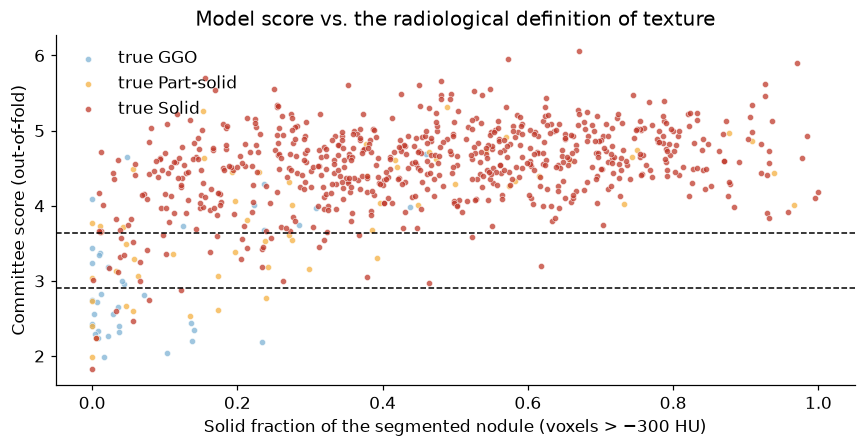

Spearman ρ(solid fraction, committee score) = 0.44


In [20]:
solid_fraction = train['comp_solid_fraction'].values
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, name in enumerate(U.CLASS_NAMES):
    m = y == k
    ax.scatter(solid_fraction[m], oof_score[m], s=16, alpha=0.75, color=U.CLASS_COLORS[name],
               edgecolor='white', linewidth=0.4, label=f'true {name}')
for t in (low, high):
    ax.axhline(t, color='black', ls='--', lw=1)
ax.set(xlabel='Solid fraction of the segmented nodule (voxels > −300 HU)',
       ylabel='Committee score (out-of-fold)', title='Model score vs. the radiological definition of texture')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()
print(f'Spearman ρ(solid fraction, committee score) = {spearmanr(solid_fraction, oof_score)[0]:.2f}')

Nodules with almost no solid tissue get low scores (GGO territory), and the score rises with
the solid fraction — the clinical logic is there. But the relationship is loose (ρ ≈ 0.4): many
solid nodules with a low solid fraction still get a high score, because the model also reads the
texture features. That is why it beats the one-feature rule: it corrects the solid fraction when
our segmentation includes too much soft border around a solid nodule.

## 11. Does it work equally well for every kind of nodule?
**Fairness note.** LNDb's public tables contain no patient demographics (the anonymised birth
year and sex are not distributed with the annotations), so we cannot audit performance by age or
sex — a limitation stated in the ethics document. What we *can* check is robustness across
**types of nodules and acquisition conditions** that could be systematically disadvantaged.

Because QWK is unstable on small groups with few rare-class nodules, we report two simpler
numbers per group: **accuracy** and the **mean absolute error of the score** (how far, on the 1–5
scale, the committee's score is from the radiologists' average).

In [21]:
sub = train[['texture_class', 'Text', 'is_small', 'seg_status', 'n_readers']].copy()
sub['correct'] = oof['Score committee'] == y
sub['abs_error'] = np.abs(oof_score - score)
sub['dice'] = train['dice_vs_radiologist']     # NaN for nodules < 3 mm (no radiologist mask)

GROUP_DEFS = {
    'Nodule size': np.where(sub.is_small, '< 3 mm (no radiologist mask)', '≥ 3 mm'),
    'Segmentation': np.select([sub.seg_status == 'fallback', sub.seg_status == 'clipped'],
                              ['fallback sphere', 'clipped by lung border'], 'normal'),
    'Segmentation quality (Dice)': pd.cut(sub.dice, [0, 0.5, 0.75, 1], labels=['< 0.50', '0.50–0.75', '> 0.75'])
                                     .astype(str).replace('nan', 'no mask (< 3 mm)'),
    'Radiologists who read it': np.where(sub.n_readers >= 2, '2 or more', 'only 1'),
    'True class': train['texture_name'].values,
}
rows = []
for dimension, labels_ in GROUP_DEFS.items():
    for g, part in sub.groupby(pd.Series(labels_, index=sub.index)):
        rows.append({'dimension': dimension, 'group': g, 'nodules': len(part),
                     'accuracy': part.correct.mean(), 'mean |score error|': part.abs_error.mean()})
fair = pd.DataFrame(rows).set_index(['dimension', 'group'])
fair.style.format({'nodules': '{:.0f}', 'accuracy': '{:.0%}', 'mean |score error|': '{:.2f}'})

**Reading the table:**
- **Nodule size:** small nodules (< 3 mm) are rated only slightly less accurately than larger ones
  (86% vs 87%) — no group is left behind because it is small.
- **Segmentation quality matters:** when our segmentation was clipped at the lung border or
  disagrees with the radiologist (Dice < 0.5), accuracy drops to ~80% (vs ~94% when Dice > 0.75).
  This is the same cost of automation measured in section 9, seen nodule by nodule.
- **Label quality matters:** nodules read by a single radiologist have noisier labels (no
  averaging), so part of the lower accuracy there is label noise, not model error.
- **The largest gap is by true class:** GGO and above all part-solid are harder — a consequence of
  having few examples. It is the main risk of the system and the reason for the referral mechanism
  below.

## 12. Knowing when to ask for help
A second reader is more useful if it says **"I'm not sure about this one"**. The committee gives a
natural confidence measure: **how far the score is from the nearest cut-off**. A nodule scoring
4.6 is clearly solid; one scoring 3.6, right on the part-solid/solid border, is not.

The question is whether that confidence is *useful*: if the model hands back its most uncertain
nodules to the radiologist, how many of its **mistakes** go with them? A useless confidence
measure would catch errors at the same rate as a random selection (the diagonal).

(We do not use QWK here: removing the borderline nodules removes mostly part-solid ones, and
QWK on the remaining, even more imbalanced set is not comparable. Errors caught and accuracy are.)

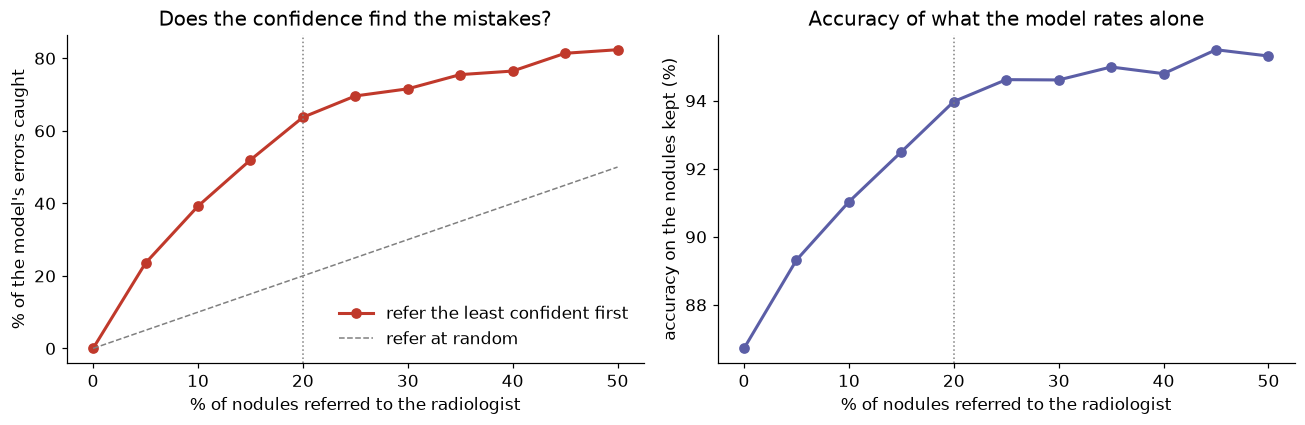

Referring the 20% least confident nodules:
  errors caught                      : 64% of all the model's errors
  accuracy on the remaining nodules  : 94.0%  (vs 86.7% on all)
  part-solid nodules referred        : 30 of 60


In [22]:
margin = np.array([min(abs(s - fold_thresholds[f][0]), abs(s - fold_thresholds[f][1]))
                   for s, f in zip(oof_score, train.fold)])
order = np.argsort(margin)                     # most uncertain first
wrong = oof['Score committee'] != y

curve = []
for r in np.arange(0, 0.505, 0.05):
    n_ref = int(round(r * len(order)))
    ref, keep = order[:n_ref], order[n_ref:]
    curve.append({'referred': r, 'errors caught': wrong[ref].sum() / wrong.sum(),
                  'accuracy on kept': 1 - wrong[keep].mean()})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(curve.referred * 100, curve['errors caught'] * 100, marker='o', color=U.COLOR_ACCENT, lw=2,
             label='refer the least confident first')
axes[0].plot([0, 50], [0, 50], color='gray', ls='--', lw=1, label='refer at random')
axes[0].set(xlabel='% of nodules referred to the radiologist', ylabel='% of the model\'s errors caught',
            title='Does the confidence find the mistakes?')
axes[0].legend(frameon=False, loc='lower right')
axes[1].plot(curve.referred * 100, curve['accuracy on kept'] * 100, marker='o', color=U.COLOR_NEUTRAL, lw=2)
axes[1].set(xlabel='% of nodules referred to the radiologist', ylabel='accuracy on the nodules kept (%)',
            title='Accuracy of what the model rates alone')
for ax in axes:
    ax.axvline(REFER_RATE * 100, color='gray', ls=':', lw=1)
plt.tight_layout(); plt.show()

row = curve.loc[np.isclose(curve.referred, REFER_RATE)].iloc[0]
referred = order[:int(round(REFER_RATE * len(order)))]
print(f'Referring the {REFER_RATE:.0%} least confident nodules:')
print(f'  errors caught                      : {row["errors caught"]:.0%} of all the model\'s errors')
print(f'  accuracy on the remaining nodules  : {row["accuracy on kept"]:.1%}  (vs {1 - wrong.mean():.1%} on all)')
print(f'  part-solid nodules referred        : {(y[referred] == 1).sum()} of {(y == 1).sum()}')

**Why this matters for the business case.** The confidence measure works: referring 20% of
the nodules catches about **64% of the model's mistakes** (three times more than referring at
random), and the accuracy on the nodules the model keeps rises from ≈ 87% to ≈ 94%. The referred
group also contains about half of all part-solid nodules — exactly the ones that deserve a second
look. The model does not need to be perfect to be useful: handling the clear majority
automatically and sending a small, *targeted* share to a human is a realistic clinical workflow.

## 13. Final texture model
The final texture model is the score committee, refitted on all 768 nodules (hyper-parameters and
cut-offs are re-tuned by its internal cross-validation). We also show, for comparison, what the
QWK-optimised cut-offs would have been (section 6.3). It is saved with
the list of features it expects (`outputs/texture_model.joblib`).

In [23]:
final_model = M.TextureScoreCommittee(selection=selection, n_jobs=N_JOBS, memory=memory).fit(X, score, groups)

joblib.dump({'model': final_model, 'features': features, 'class_names': U.CLASS_NAMES,
             'class_to_score': U.CLASS_TO_SCORE}, U.OUTPUT_DIR / 'texture_model.joblib')

# Out-of-fold predictions, kept for the report / video
train[['LNDbID', 'FindingID', 'fold', 'texture_name', 'Text']].assign(
    committee_score=oof_score.round(3),
    predicted=[U.CLASS_NAMES[k] for k in oof['Score committee']],
    **{f'pred_{k}': [U.CLASS_NAMES[c] for c in oof[k]] for k in ['KNN', 'SVM', 'MLP']},
).to_csv(U.OUTPUT_DIR / 'cv_predictions.csv', index=False)

final_oof = np.mean(list(final_model.oof_scores_.values()), axis=0)
qwk_cut = M.tune_thresholds(final_oof, y)
print(f'Cut-offs (prevalence matching): {final_model.thresholds_}')
print(f'For comparison, QWK-optimised cut-offs on all {len(final_oof)} nodules would be {qwk_cut} → '
      f'{(M.score_to_class(final_oof, qwk_cut) == 1).sum()} part-solid predictions out of {len(final_oof)} '
      f'(vs {(y == 1).sum()} real ones)')
pd.DataFrame(final_model.best_params_).T.rename_axis('member')

Cut-offs (prevalence matching): (2.831, 3.603)
For comparison, QWK-optimised cut-offs on all 768 nodules would be (2.65, 3.5) → 55 part-solid predictions out of 768 (vs 60 real ones)


,n_neighbors,n_features,C,alpha
member,,,,
KNN,15.0,50.0,NaN,NaN
SVM,NaN,all,10,NaN
MLP,NaN,all,NaN,10.0


In [24]:
shutil.rmtree(CACHE_DIR, ignore_errors=True)    # remove the temporary pipeline cache

## Summary

In [25]:
final = pd.DataFrame({
    'QWK (out-of-fold)': {k: results[k]['QWK'] for k in ORDER},
    '95% CI': {k: results[k]['QWK 95% CI'] for k in ORDER},
    'Balanced acc.': {k: results[k]['Balanced acc.'] for k in ORDER},
    'Recall part-solid': {k: results[k]['Recall Part-solid'] for k in ORDER},
}).rename(index=labels)
final.loc['Radiologist vs radiologist'] = [HUMAN_QWK, '', np.nan, np.nan]
final.style.format({'QWK (out-of-fold)': '{:.3f}', 'Balanced acc.': '{:.3f}', 'Recall part-solid': '{:.3f}'},
                   na_rep='—')

,QWK (out-of-fold),95% CI,Balanced acc.,Recall part-solid
"Always ""solid""",0.000,0.00 – 0.00,0.333,0.000
Solid-fraction rule,0.452,0.34 – 0.54,0.501,0.117
KNN,0.289,0.20 – 0.37,0.550,0.350
SVM,0.539,0.41 – 0.64,0.551,0.200
MLP (neural net),0.518,0.40 – 0.61,0.526,0.133
Logistic regression,0.434,0.32 – 0.52,0.509,0.183
Score committee (ours),0.587,0.46 – 0.68,0.571,0.217
Radiologist vs radiologist,0.566,,—,—


### Conclusions
1. **Texture can be rated automatically, close to the consistency of a second radiologist.** Our
   score committee reaches QWK ≈ 0.59 against ≈ 0.57 between two radiologists, from the nodule's
   position alone and with a fully automatic pipeline.
2. **Framing the problem mattered more than the choice of algorithm.** Predicting the
   radiologists' average *score* instead of three unordered classes improved KNN, SVM and MLP alike,
   and averaging the three gave the best model. The final step — turning the score into a class —
   was designed for robustness (prevalence matching), after seeing that optimising the metric
   directly can make the part-solid class disappear.
3. **The hard part is part-solid vs solid**, the same distinction radiologists disagree on. Part-solid
   recall is low (≈ 0.22 at our operating point) — the main clinical limitation. The model's
   confidence flags these cases: referring 20% of nodules catches ~64% of its errors.
4. **Automation has a measurable but moderate cost** (≈ 0.04 QWK vs radiologist outlines).
5. **The model is interpretable at the level clinicians care about**: it reads texture at specific
   scales (wavelet / LoG filters, GLCM and NGTDM matrices) and follows the solid-fraction logic of
   the radiological definition.

### Limitations
- Few rare cases (38 GGO, 60 part-solid) → wide confidence intervals; results on rare classes are fragile.
- Labels are subjective; nodules read by one radiologist carry more label noise.
- A single hospital (CHUSJ) — generalisation to other centres and scanners is untested.
- No demographic data → fairness by age or sex cannot be audited.

### What happened next
Malignancy became the target (Notebooks 1–6). This texture model was also validated externally on
LIDC-IDRI's texture ratings (a different country, hospitals and scanners): QWK ≈ 0.47 there, against
≈ 0.58 between LIDC radiologists — it generalises partly. Used as an extra input of the malignancy
model it did not help, so the final model does not use it.